# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import SatelliteBuildingsDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 6031


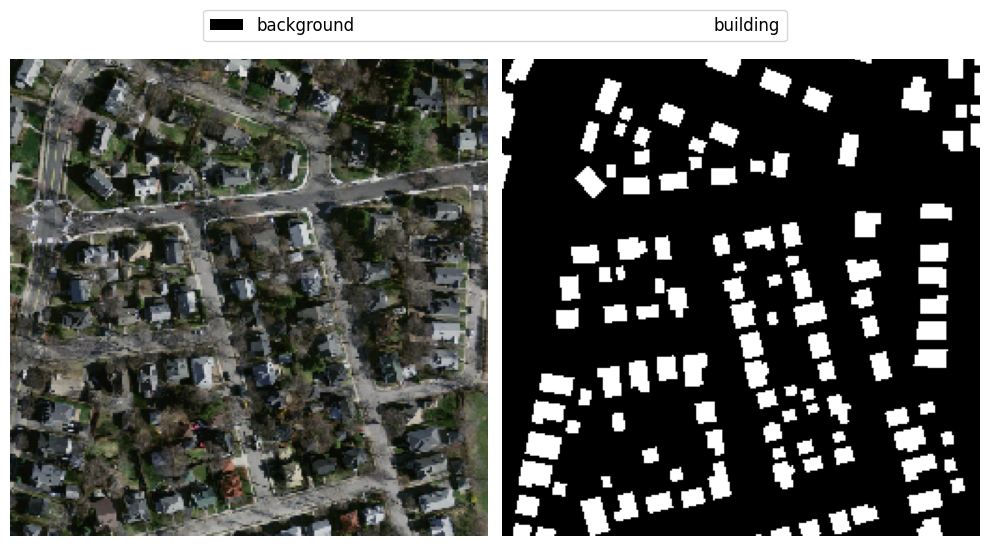

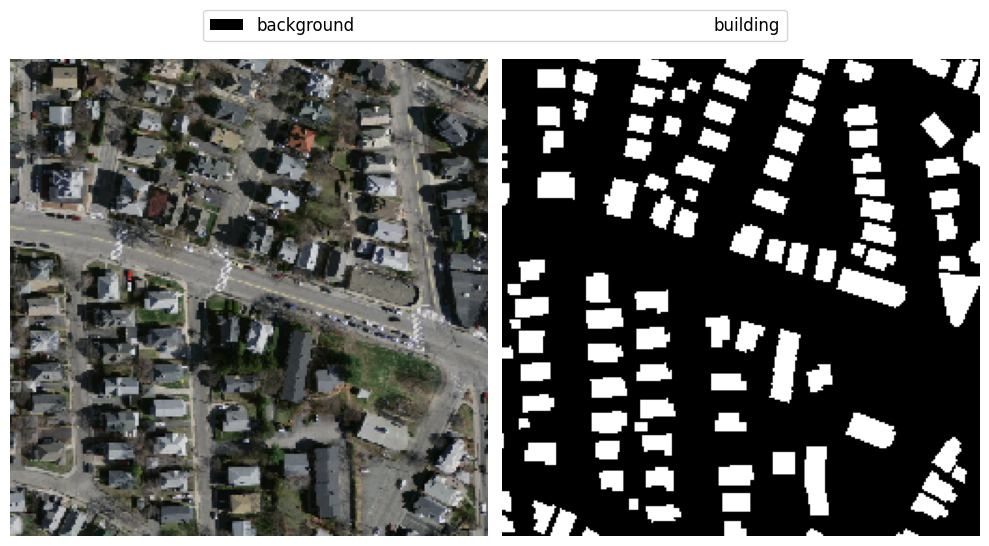

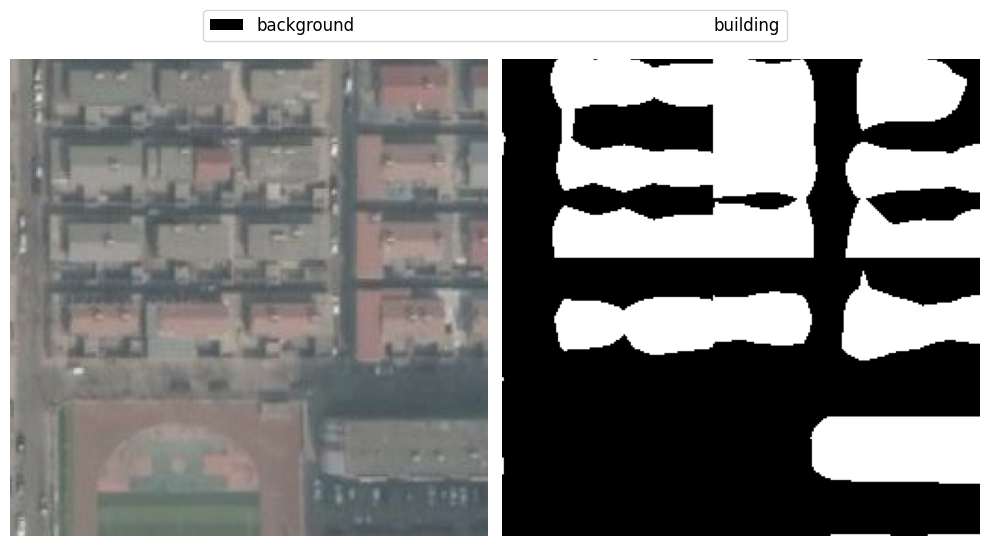

In [9]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/satellite_buildings"
}
dataset = SatelliteBuildingsDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [10]:
dataset.data_distribution_table()

,Number of pixels
background,317580780.0
building,79960596.0


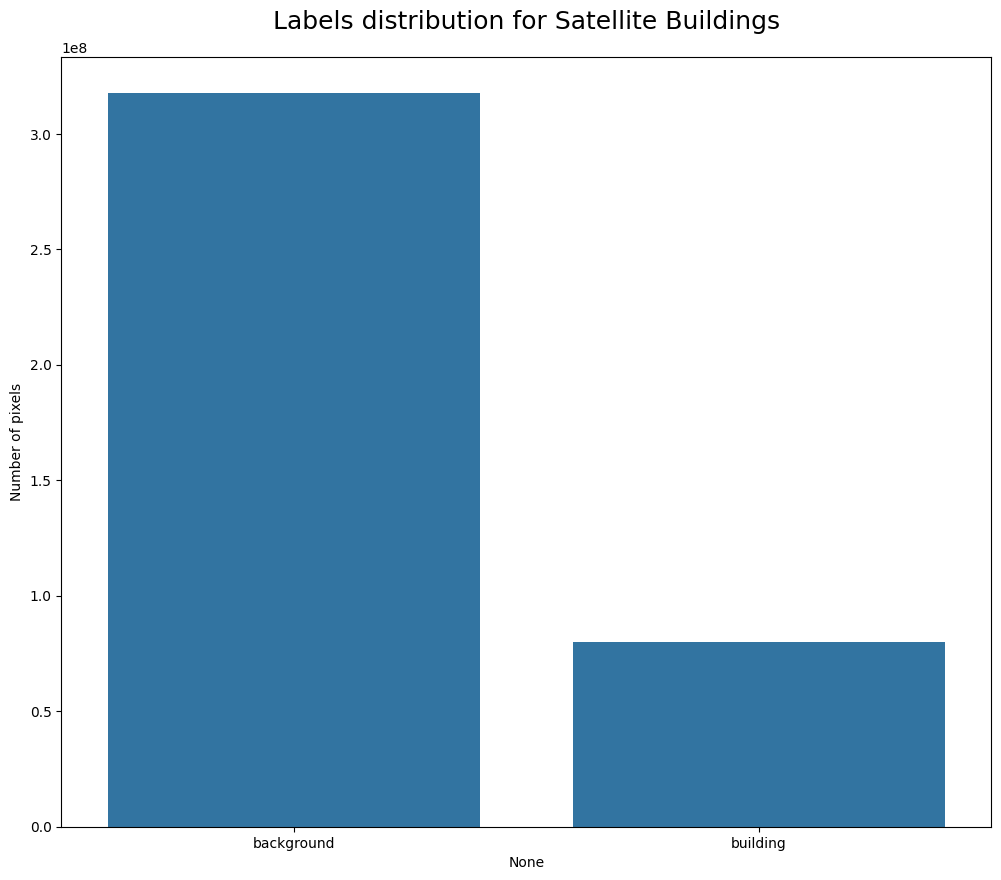

In [11]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 19,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/satellite_buildings/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = SatelliteBuildingsDataset(train_dataset_config)
len(train_dataset)

6023

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/satellite_buildings"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-06 07:53:14,149 INFO Starting training.
training: 100%|██████████| 317/317 [04:35<00:00,  1.15it/s]
2025-03-06 07:57:49,451 INFO epoch: 1, time: 275, loss:  0.21766
testing on train set: 100%|██████████| 317/317 [04:34<00:00,  1.15it/s]
2025-03-06 08:02:25,868 INFO IOU:0.8388897537060701, IOU mean:0.7718376628623078, IOU per Class:[0.90055853 0.6431168 ]
training: 100%|██████████| 317/317 [04:34<00:00,  1.16it/s]
2025-03-06 08:07:00,058 INFO epoch: 2, time: 275, loss:  0.11428
testing on train set: 100%|██████████| 317/317 [04:34<00:00,  1.15it/s]
2025-03-06 08:11:35,035 INFO IOU:0.8648842192412121, IOU mean:0.8013146602497156, IOU per Class:[0.91445839 0.68817093]
training: 100%|██████████| 317/317 [04:36<00:00,  1.15it/s]
2025-03-06 08:16:11,304 INFO epoch: 3, time: 276, loss:  0.08643
testing on train set: 100%|██████████| 317/317 [04:34<00:00,  1.15it/s]
2025-03-06 08:20:46,234 INFO IOU:0.8827207183080212, IOU mean:0.8252435239771654, IOU per Class:[0.9256084  0.72487865]
t

## Evaluate the model

In [13]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/satellite_buildings/test",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = SatelliteBuildingsDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/satellite_buildings/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

8


2025-03-06 11:37:58,383 INFO Loading checkpoint /home/dragik/data/FAIR_EO/satellite_buildings/checkpoint.pth.tar
2025-03-06 11:37:58,856 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/satellite_buildings/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2/2 [00:07<00:00,  3.87s/it]


[{'IOU': 0.7961215723880092,
  'IOU mean': 0.7744552037175351,
  'IOU per Class': array([0.8359587 , 0.71295171])}]

## Predictions

2025-03-10 09:41:59,040 INFO Loading checkpoint /home/dragik/data/FAIR_EO/satellite_buildings/checkpoint.pth.tar
2025-03-10 09:41:59,660 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/satellite_buildings/checkpoint.pth.tar at epoch 11


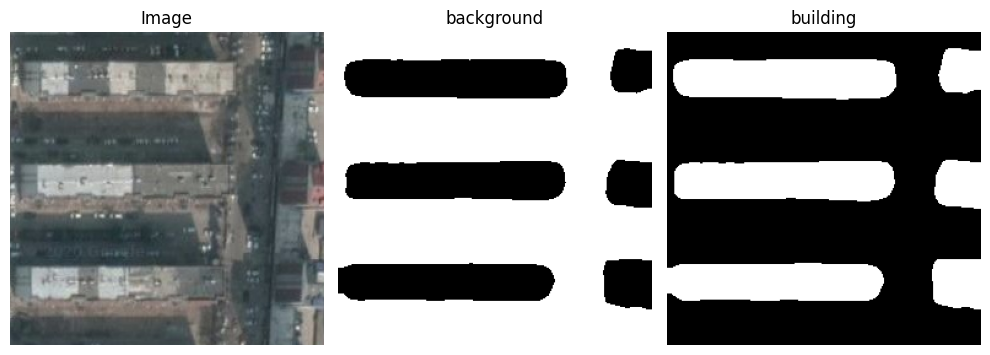

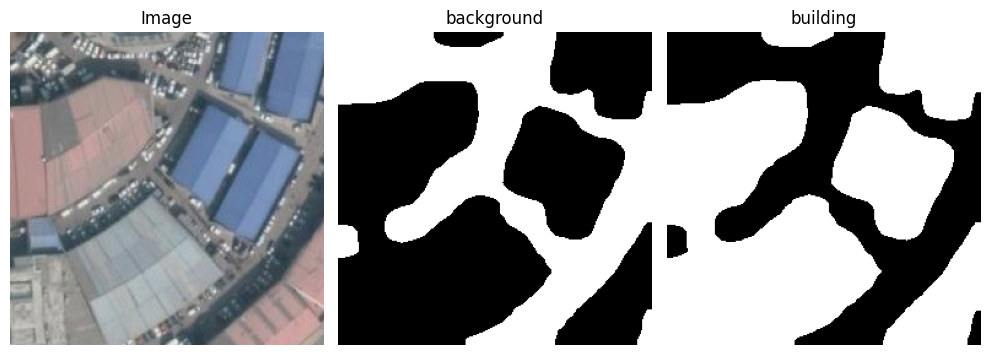

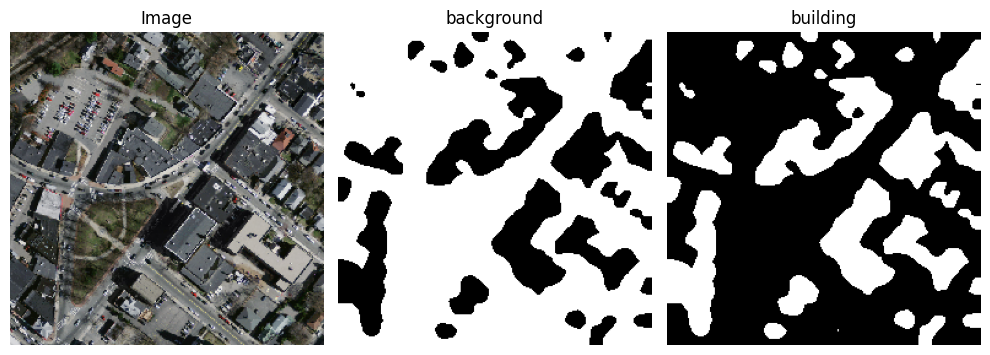

In [6]:
model_path = "/home/dragik/data/FAIR_EO/satellite_buildings/checkpoint.pth.tar"
labels = ["background","building"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/satellite_buildings/test/src/T25.png')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/satellite_buildings/test/src/T41.png')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/satellite_buildings/test/src/W1299.png')
fig = model.predict_masks(image, labels, transform)